> **Plan** (delete once the sections carry it). An ETL pipeline computes over a set of inputs in stages, and the ledger recomputes only the stages whose inputs moved.
>
> 1. **Setup: the city data**: each city's year of daily weather is a sealed value found by an alias; the city set the pipeline runs over is rows.
> 2. **A pipeline of stages**: a daily comfort per city (its weather plus a comfort column), a city comfort per city over a date range (the days binned by comfort level), a comfort report over a city set and a date range; asked once, every stage runs; asked again, every stage is a hit.
> 3. **Summer, and one more city**: one edit narrows the range to summer and adds a city; only the new city's daily comfort runs, then every city's summer binning and the report.
> 4. **Changing a city's data**: only that city's daily comfort and what is downstream of it run.
> 5. **Changing one stage's code**: only that stage runs; the stages below it are hits.
>
> Each section ends on the count of stages that ran, read off the ledger.

#### Setup

In [1]:
import math
import os
import random
import shutil
import subprocess
import sys
import tempfile
from datetime import date, timedelta
from importlib.resources import files
from pathlib import Path

from IPython.display import SVG, Code, display

from dvc_dat.ledger import Ledger, bump

for module_name in [m for m in sys.modules if m == "comfort" or m.startswith("comfort.")]:
    del sys.modules[module_name]                  # a re-run: forget the last run's code repo
sys.path[:] = [p for p in sys.path if not p.endswith("/comfort-repo")]
scratch_path = Path(tempfile.mkdtemp(prefix="demo-etl-"))
repo_path = scratch_path / "comfort-repo"      # the code's repo, a copy of comfort-repo/ beside this notebook
shutil.copytree("comfort-repo", repo_path, ignore=shutil.ignore_patterns("__pycache__"))


def show(name: str) -> None:
    """A module of the code's repo (`comfort/stages.py`) shown as code, or the figure `<name>.svg` beside this notebook."""
    if name.endswith(".py"):
        print(f"comfort-repo/{name}")
        display(Code(filename=str(repo_path / name), language="python"))
    else:
        display(SVG(filename=f"{name}.svg"))


def git(*args: str) -> str:
    """Run git in the code's repo; return its stdout."""
    cmd = ["git", "-c", "user.name=demo", "-c", "user.email=demo@example.com",
           "-c", "init.defaultBranch=main", *args]
    done = subprocess.run(cmd, cwd=repo_path, check=True, capture_output=True, text=True)
    return done.stdout.strip()


def commit(message: str, *rels: str) -> None:
    """Commit files of the code's repo; re-running with the same files commits nothing."""
    git("add", *rels)
    if git("status", "--porcelain", "--", *rels):
        git("commit", "-q", "-m", message)


git("init", "-q")
commit("comfort: the stages", "comfort")
(repo_path / ".datconfig.yaml").write_text(     # for `just`: the ledger, and a main importing comfort
    "ledger: ../ledger\n"
    'run: python3 -c "import sys, comfort; from dvc_dat import Dat; sys.exit(Dat.cli_main())"\n')
(repo_path / "justfile").write_text(
    f"import '{files('dvc_dat') / 'dvc_dat.just'}'  # run\n"
    f"import '{Path('justfile').resolve()}'  # the demo's ledger verbs\n")
os.environ["PATH"] = f"{Path(sys.executable).parent}:{os.environ['PATH']}"   # `just run` execs this venv's python3
sys.path.insert(0, str(repo_path))
L = Ledger(scratch_path / "ledger", create=True)

STAGES = ("comfort.stages.daily_comfort", "comfort.stages.city_comfort", "comfort.report.comfort_report")


def entry_counts() -> dict:
    """How many results each stage has sealed on the ledger so far."""
    rev = L.at()
    return {name.rsplit(".", 1)[1]: len(rev.refs(fn=name)) for name in STAGES}


def ran_since(counts_before: dict) -> dict:
    """How many times each stage ran (missed and sealed) since `counts_before`."""
    counts_now = entry_counts()
    return {stage: counts_now[stage] - counts_before[stage] for stage in counts_now}

# ETL pipelines: computing, recomputing only what moved

An ETL pipeline is a series of stages, each computing a value from the values of the stage below it, over a set of inputs.
Every stage here is a ledger function, so every result is a value sealed with its dependencies, the exact inputs and code it was computed from.
Asked for a result, the ledger hands back a sealed one whose dependencies still hold and runs the stage only when one of its dependencies has moved.
So a change anywhere in the pipeline recomputes that stage and what is downstream of it, and nothing else.

## Setup: the city data

The task: five cities each report a year of weather, a date, a temperature and a humidity per day; a city set names the representative cities a report covers.
The pipeline adds a comfort score to each city's days, bins a city's days by comfort level over a date range, and reports the city set's comfortable days and its two most comfortable cities over that range.
Every input is a ledger write, so every change to one is something the pipeline can see.
Each city's weather is a value found by the alias `weather/<city>`; the city set, a few representative cities, is held as `contains` rows on its own subject.

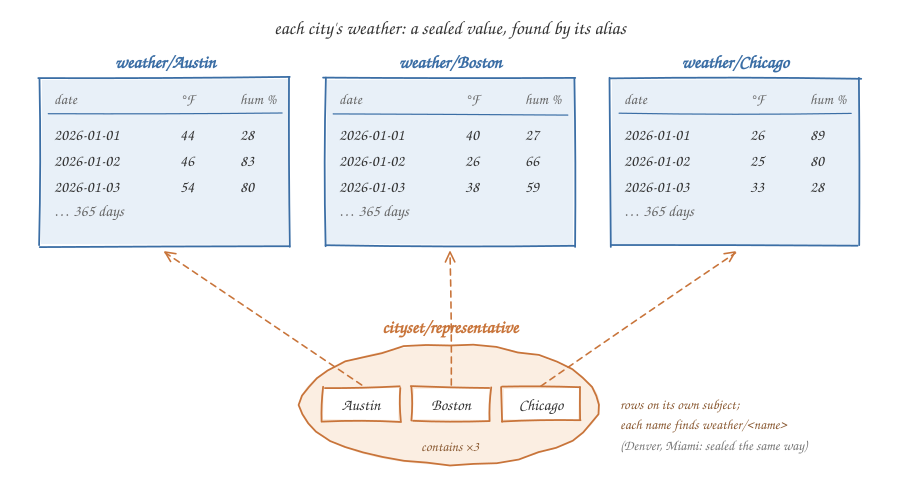

In [2]:
show("demo-etl-data")

### The value kinds

Two kinds of value: a city's days, one row per day, `[date, °F, humidity %]` as reported and with a comfort column once scored, and a comfort count, the count of days at each of ten comfort levels.
The code lives in `comfort-repo/` beside this notebook, plain Python files; setup copies it into a scratch git repo, since a stage's code is identified by the files its repo holds, and `show` prints a module.

In [3]:
show("comfort/values.py")

comfort-repo/comfort/values.py


"""`comfort.values`: a city's days and a comfort count."""
import json

from dvc_dat.ledger import Value, ledger_class


@ledger_class(preds=("city",))
class Days(Value):
    """A city's days: one row per day, [date, °F, humidity %], and its comfort once scored."""

    def __init__(self, days):
        self.days = [list(day) for day in days]

    def encode(self) -> bytes:
        return json.dumps(self.days).encode()

    @classmethod
    def decode(cls, data: bytes, store) -> "Days":
        return cls(json.loads(data))


@ledger_class(preds=("city",))
class ComfortCounts(Value):
    """How many of a city's days sit at each comfort level, 0 (miserable) to 9 (ideal)."""

    def __init__(self, counts):
        self.counts = list(counts)

    def encode(self) -> bytes:
        return json.dumps(self.counts).encode()

    @classmethod
    def decode(cls, data: bytes, store) -> "ComfortCounts":
        return cls(json.loads(data))

In [4]:
from comfort.values import Days

### Five cities' weather

Each city's temperature follows the seasons around its own yearly mean, so summer and winter differ.

In [5]:
MEAN_F = {"Austin": 69, "Boston": 52, "Chicago": 50, "Denver": 51, "Miami": 77}


def seal_weather(city: str, seed: int) -> None:
    """Seal a year of a city's weather drawn from `seed`, and point `weather/<city>` at it."""
    rng = random.Random(seed)
    days = []
    for n in range(365):
        season = -math.cos(2 * math.pi * (n - 15) / 365)    # -1 mid-January, +1 mid-July
        temp = round(MEAN_F[city] + 20 * season + rng.uniform(-8, 8))
        days.append([(date(2026, 1, 1) + timedelta(n)).isoformat(), temp, rng.randrange(20, 90)])
    weather_value = Days(days)
    weather_value.preds["city"] = city
    with L.transaction(by="human:dan", why=f"{city}'s data") as t:
        weather_value.seal(t, name=f"weather/{city}")


for city, seed in [("Austin", 1), ("Boston", 2), ("Chicago", 3), ("Denver", 4), ("Miami", 5)]:
    seal_weather(city, seed)
print(L.at().load("weather/Austin").days[:3])
# → [['2026-01-01', 44, 28], ['2026-01-02', 46, 83], ['2026-01-03', 54, 80]]

[['2026-01-01', 44, 28], ['2026-01-02', 46, 83], ['2026-01-03', 54, 80]]


### The city set

A city set is rows: `cityset/representative contains Austin`, one per city; `contains` is declared many-valued, so the rows add up to a set.
`all` answers in revision order, the order the rows were added.

In [6]:
with L.transaction(by="human:dan", why="the city set") as t:
    t.add("db/pred/contains", "db/cardinality", "many")
    for city in ("Boston", "Austin", "Chicago"):
        t.add("cityset/representative", "contains", city)
print(L.at().all("cityset/representative", "contains"))
# → ['Boston', 'Austin', 'Chicago']

['Boston', 'Austin', 'Chicago']


## A pipeline of stages

Three stages, each a ledger function running the one below it: a daily comfort per city, a city comfort per city over a date range, and a comfort report over a city set and a date range.

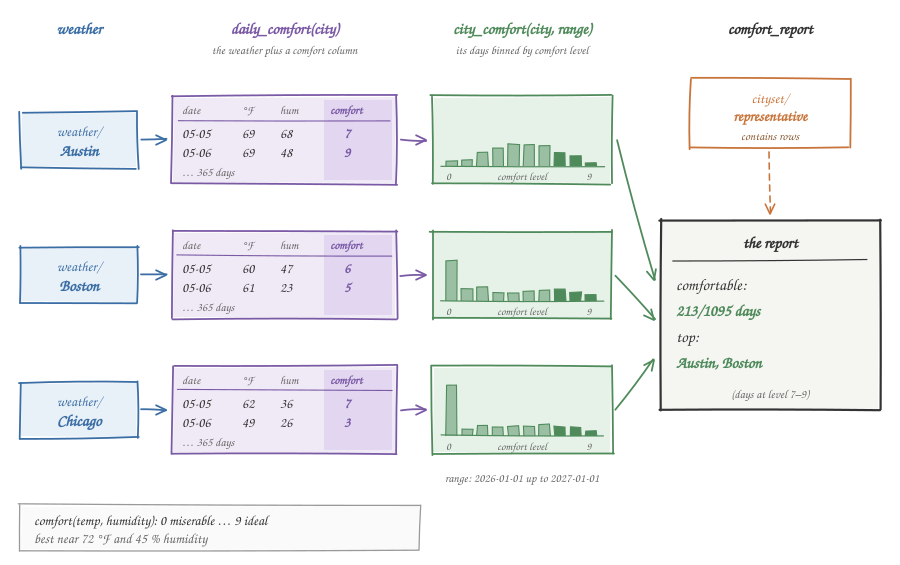

In [7]:
show("demo-etl-pipeline")

### The stages

`daily_comfort` adds a column, a comfort score per day; `city_comfort` bins those days by comfort level, keeping only the days in its range; a range is a half-open pair of dates, `start` up to `end`.

In [8]:
show("comfort/stages.py")

comfort-repo/comfort/stages.py


"""`comfort.stages`: a city's daily comfort, and its days binned by comfort level over a date range."""
from dvc_dat.ledger import ledger_fn

from .values import ComfortCounts, Days


def comfort(temp: int, humidity: int) -> int:
    """A day's comfort, 0 (miserable) to 9 (ideal): best near 72 °F and 45 % humidity."""
    return max(0, 9 - abs(temp - 72) // 4 - abs(humidity - 45) // 10)


@ledger_fn
def daily_comfort(rev, *, city: str) -> Days:
    """A city's days with a comfort column added: [date, °F, humidity %, comfort]."""
    weather = rev.load(f"weather/{city}")   # traced: the alias and the bytes it names
    days = Days([[day, temp, humidity, comfort(temp, humidity)] for day, temp, humidity in weather.days])
    days.preds["city"] = city
    return days


@ledger_fn
def city_comfort(rev, *, city: str, start: str, end: str) -> ComfortCounts:
    """A city's days from `start` up to `end`, counted per comfort level."""
    days = rev.run("comfort.stages.daily_comfort", city=city)
    counts = [0] * 10
    for day, _temp, _humidity, level in days.days:
        if start <= day < end:
            counts[level] += 1
    comfort_counts = ComfortCounts(counts)
    comfort_counts.preds["city"] = city
    return comfort_counts

In [9]:
show("comfort/report.py")

comfort-repo/comfort/report.py


"""`comfort.report`: the most comfortable cities in a city set."""
from dvc_dat.ledger import ledger_fn


@ledger_fn
def comfort_report(rev, *, cityset: str, start: str, end: str) -> dict:
    """The city set's share of comfortable days (level 7+) from `start` up to `end`, and its two most comfortable cities."""
    cities = sorted(rev.all(cityset, "contains"))   # traced: the set's rows; sorted, so a tie breaks by name, not by when a city joined
    counts = {c: rev.run("comfort.stages.city_comfort", city=c, start=start, end=end).counts for c in cities}
    good = {c: sum(n[7:]) for c, n in counts.items()}
    top = sorted(cities, key=lambda c: -good[c])[:2]
    return {"comfortable": f"{sum(good.values())}/{sum(sum(n) for n in counts.values())} days", "top": top}

### Mounting the code

Mounting `comfort` makes its stages sandboxed: each call runs in a fresh process of its own, and its code is the hash of every module file the run loaded.
A `# same as` line is the shell form, typed in the code's repo, whose justfile imports `run` from dvc-dat (`dvc_dat.just`) and the ledger verbs from the `justfile` beside this notebook.

In [10]:
with L.transaction(by="human:dan", why="mount the stages", lock=10) as t:
    t.add("db/mount/comfort", "db/root", "comfort")
    t.add("db/mount/comfort", "db/repo", "comfort-repo")
    bump(t, "code/comfort-repo", "minor", confirm=lambda old, new: True)   # 0.1.0, at HEAD
print("sandboxed:", L.at().load_fn("comfort.report.comfort_report").code.sandboxed)
# → sandboxed: True
# the bump, same as:
#   echo yes | just bump code minor

sandboxed: True


### Asking for the comfort report

`rev.run(name, **keys)` returns the stage's result, running it only when no sealed result whose dependencies hold answers the same question.
The first report covers the whole year.

In [11]:
counts_before = entry_counts()
comfort_report_value = L.at().run("comfort.report.comfort_report", cityset="cityset/representative",
                                  start="2026-01-01", end="2027-01-01")
print(comfort_report_value.obj)
# → {'comfortable': '213/1095 days', 'top': ['Austin', 'Boston']}
print(ran_since(counts_before))
# → {'daily_comfort': 3, 'city_comfort': 3, 'comfort_report': 1}
# same as:
#   just run comfort.report.comfort_report cityset=cityset/representative start="'2026-01-01'" end="'2027-01-01'"

{'comfortable': '213/1095 days', 'top': ['Austin', 'Boston']}
{'daily_comfort': 3, 'city_comfort': 3, 'comfort_report': 1}


Everything ran: a daily comfort per city, a city comfort per city over the year, and the comfort report.

In [12]:
counts_before = entry_counts()
again_value = L.at().run("comfort.report.comfort_report", cityset="cityset/representative",
                         start="2026-01-01", end="2027-01-01")
print(again_value.subject == comfort_report_value.subject)
# → True
print(ran_since(counts_before))
# → {'daily_comfort': 0, 'city_comfort': 0, 'comfort_report': 0}
# same as (a hit):
#   just run comfort.report.comfort_report cityset=cityset/representative start="'2026-01-01'" end="'2027-01-01'"

True
{'daily_comfort': 0, 'city_comfort': 0, 'comfort_report': 0}


Asked again, nothing ran: the comfort report is a hit.
In practice a pipeline is asked for from the shell, and `just run` is this same `rev.run` call: here, a third hit.

In [13]:
!cd {repo_path} && just run comfort.report.comfort_report cityset=cityset/representative start="'2026-01-01'" end="'2027-01-01'"
# → hit  #<8 hex>

hit  #c898c8e3


## Summer, and one more city

Two changes at once: Denver joins the set, and the report is asked for summer, June through August.
A new range is a new question for every city comfort; the daily comfort under it does not depend on the range, so only the new city's runs.

In [14]:
with L.transaction(by="human:dan", why="Denver joins") as t:
    t.add("cityset/representative", "contains", "Denver")
counts_before = entry_counts()
comfort_report_value = L.at().run("comfort.report.comfort_report", cityset="cityset/representative",
                                  start="2026-06-01", end="2026-09-01", path="report/summer")
print(comfort_report_value.obj)
# → {'comfortable': '175/368 days', 'top': ['Denver', 'Boston']}
print(ran_since(counts_before))
# → {'daily_comfort': 1, 'city_comfort': 4, 'comfort_report': 1}
# the run, same as:
#   just run comfort.report.comfort_report cityset=cityset/representative start="'2026-06-01'" end="'2026-09-01'" alias=report/summer

{'comfortable': '175/368 days', 'top': ['Denver', 'Boston']}
{'daily_comfort': 1, 'city_comfort': 4, 'comfort_report': 1}


Denver's daily comfort ran; Austin's, Boston's and Chicago's were hits, scored once for the year and binned again for summer.
All four city comforts ran over the new range, and the report ran once.

## Changing a city's data

A new version of a city's weather is a new value with the alias re-pointed, so every result that loaded the alias is stale.

In [15]:
seal_weather("Boston", seed=22)                 # Boston re-reported
counts_before = entry_counts()
comfort_report_value = L.at().run("comfort.report.comfort_report", cityset="cityset/representative",
                                  start="2026-06-01", end="2026-09-01", path="report/summer")
print(ran_since(counts_before))
# → {'daily_comfort': 1, 'city_comfort': 1, 'comfort_report': 1}
# the run, same as:
#   just run comfort.report.comfort_report cityset=cityset/representative start="'2026-06-01'" end="'2026-09-01'" alias=report/summer

{'daily_comfort': 1, 'city_comfort': 1, 'comfort_report': 1}


Boston's daily comfort ran, then its summer city comfort and the report; the other three cities were hits, since they never read `weather/Boston`.

## Changing one stage's code

An edit to one stage's module changes that stage's code hash, so that stage reruns; stages whose runs never loaded the module are hits.

In [16]:
report_path = repo_path / "comfort/report.py"
report_source = report_path.read_text().replace("[:2]", "[:1]").replace("two most comfortable cities", "most comfortable city")
report_path.write_text(report_source)
commit("report: the one most comfortable city", "comfort/report.py")
counts_before = entry_counts()
comfort_report_value = L.at().run("comfort.report.comfort_report", cityset="cityset/representative",
                                  start="2026-06-01", end="2026-09-01", path="report/summer")
print(comfort_report_value.obj)
# → {'comfortable': '182/368 days', 'top': ['Boston']}
print(ran_since(counts_before))
# → {'daily_comfort': 0, 'city_comfort': 0, 'comfort_report': 1}
# the run, same as:
#   just run comfort.report.comfort_report cityset=cityset/representative start="'2026-06-01'" end="'2026-09-01'" alias=report/summer

{'comfortable': '182/368 days', 'top': ['Boston']}
{'daily_comfort': 0, 'city_comfort': 0, 'comfort_report': 1}


Only the comfort report ran: its run loaded `report.py`, and no other stage's run did.
No `bump` was needed: a sandboxed stage's identity is the bytes of the modules its run loaded, so the edit alone made the comfort report a new question, and a miss runs at HEAD, clean or dirty (F520 Q39).

## Reading a result's dependencies back

A result's dependencies list every input it read: each stage below by its result's bytes (`eval:`), the set's rows (`q:`, the `all` call and its answer), its own code (`code`, the snapshot, and `fn`, the function's name in it) and the environment.

In [17]:
for item in sorted(comfort_report_value.dependencies):
    print(item)
# → code
#   eval:comfort.stages.city_comfort{"city":"Austin","end":"2026-09-01","start":"2026-06-01"}
#   eval:comfort.stages.city_comfort{"city":"Boston","end":"2026-09-01","start":"2026-06-01"}
#   eval:comfort.stages.city_comfort{"city":"Chicago","end":"2026-09-01","start":"2026-06-01"}
#   eval:comfort.stages.city_comfort{"city":"Denver","end":"2026-09-01","start":"2026-06-01"}
#   fn
#   platform
#   q:{"__call__":"all","args":["cityset/representative","contains"],"since":null}
print(sorted(L.at()[comfort_report_value.dependencies["code"], "db/modules"]))
# → ['comfort/__init__.py', 'comfort/report.py', 'comfort/values.py']

code
eval:comfort.stages.city_comfort{"city":"Austin","end":"2026-09-01","start":"2026-06-01"}
eval:comfort.stages.city_comfort{"city":"Boston","end":"2026-09-01","start":"2026-06-01"}
eval:comfort.stages.city_comfort{"city":"Chicago","end":"2026-09-01","start":"2026-06-01"}
eval:comfort.stages.city_comfort{"city":"Denver","end":"2026-09-01","start":"2026-06-01"}
fn
platform
q:{"__call__":"all","args":["cityset/representative","contains"],"since":null}
['comfort/__init__.py', 'comfort/report.py', 'comfort/values.py']


`just why` reads the same back from the shell: the summer report's dependencies one level down, whether they still hold, and what moved since `report/summer`'s last target (the Boston change's report): the code alone.

In [18]:
!cd {repo_path} && just why report/summer
# → report/summer: #<8 hex>, matches the head
# → dependencies: code <8 hex>, eval:comfort.stages.city_comfort{"city":"Austin","end":"2026-09-01","start":"2026-06-01"} ComfortCounts:<8 hex>, eval:comfort.stages.city_comfort{"city":"Boston","end":"2026-09-01","start":"2026-06-01"} ComfortCounts:<8 hex>, eval:comfort.stages.city_comfort{"city":"Chicago","end":"2026-09-01","start":"2026-06-01"} ComfortCounts:<8 hex>, eval:comfort.stages.city_comfort{"city":"Denver","end":"2026-09-01","start":"2026-06-01"} ComfortCounts:<8 hex>, fn comfort.report.comfort_report, platform <platform>, query {"__call__":"all","args":["cityset/representative","contains"],"since":null} -> 4 value(s)
# → since #<8 hex>, its last target: code <8 hex> -> <8 hex>

report/summer: #2cb752f5, matches the head
dependencies: code 20224092, eval:comfort.stages.city_comfort{"city":"Austin","end":"2026-09-01","start":"2026-06-01"} ComfortCounts:b1974231, eval:comfort.stages.city_comfort{"city":"Boston","end":"2026-09-01","start":"2026-06-01"} ComfortCounts:d9690353, eval:comfort.stages.city_comfort{"city":"Chicago","end":"2026-09-01","start":"2026-06-01"} ComfortCounts:c19d2c15, eval:comfort.stages.city_comfort{"city":"Denver","end":"2026-09-01","start":"2026-06-01"} ComfortCounts:8bb8bb34, fn comfort.report.comfort_report, platform darwin-arm64-py3.12, query {"__call__":"all","args":["cityset/representative","contains"],"since":null} -> 4 value(s)
since #2977c36a, its last target: code 46f6a4ac -> 20224092


In [19]:
# clean up
shutil.rmtree(scratch_path, ignore_errors=True)   # a second run finds it gone